<a href="https://colab.research.google.com/github/miiiray/banking-intent-ai/blob/main/notebooks/01_veri_inceleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Libraries and datas**

In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split  # scikit-learn kütüphanesinden veriyi bölmeye yarayan hazır fonksiyonu alıyoruz

url = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/"
# veriyi tablo olarak işlemek için
train = pd.read_csv(url + "train.csv")
test = pd.read_csv(url + "test.csv")
#verileri yükle

print(train.shape, test.shape)
train.head() #ilk 5ini görüntüle



(10003, 2) (3080, 2)


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


**Categories**

In [28]:
counts = train["category"].value_counts()

print(counts)
print("Kategori sayısı:", len(counts))

len(counts)
print(train.isnull().sum())
print("Tekrar eden satır:", train.duplicated().sum())


category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64
Kategori sayısı: 77
text        0
category    0
dtype: int64
Tekrar eden satır: 0


**Controls and cleaning**

In [29]:

# standartlaştırma
train_key = train["text"].fillna("").str.lower().str.split().str.join(" ")
test_key = test["text"].fillna("").str.lower().str.split().str.join(" ")

print("Train boş mesaj:", train_key.eq("").sum())
print("Test boş mesaj:", test_key.eq("").sum())

print("\nTest eksik değerler:")
print(test.isnull().sum())

print("\nTrain tekrar eden mesaj:", train_key.duplicated().sum())
print("Test tekrar eden mesaj:", test_key.duplicated().sum())

# Testte de bulunan eğitim satırlarını işaretliyoruz.
overlap = train_key.isin(test_key)

print("\nTestte de bulunan eğitim satırı:", overlap.sum())

temiz = train[~overlap & ~train_key.duplicated()]
print("Önce:", len(train), "Sonra:", len(temiz))


Train boş mesaj: 0
Test boş mesaj: 0

Test eksik değerler:
text        0
category    0
dtype: int64

Train tekrar eden mesaj: 4
Test tekrar eden mesaj: 1

Testte de bulunan eğitim satırı: 7
Önce: 10003 Sonra: 9992


**Diving the data**

In [30]:

# Temizlenmiş train verisini ikiye bölüyoruz:
# train_df -> modelin öğreneceği kısım (%85)
# val_df   -> ayarları seçmek için kullanacağımız deneme sınavı (%15)
train_df, val_df = train_test_split(
    temiz,                          # bölünecek veri: temizlenmiş train tablosu
    test_size=0.15,                 # verinin %15'i validation'a ayrılsın
    stratify=temiz["category"],     # her kategorinin oranı iki parçada da aynı kalsın
    random_state=42                 # bölme her çalıştırmada aynı çıksın (ikimiz de aynı sonucu alalım)
)

# Üç parçanın boyutlarını (satır, sütun) yazdırıp kontrol ediyoruz
print("Train:", train_df.shape)       # model bununla eğitilecek
print("Validation:", val_df.shape)    # ayarlar bununla seçilecek
print("Test:", test.shape)            # final sınavı, sadece en sonda kullanılacak



Train: (8493, 2)
Validation: (1499, 2)
Test: (3080, 2)


**Label Encoding**

In [31]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()                 # isimleri sayıya çeviren araç
encoder.fit(train_df["category"])        # 77 kategoriyi SADECE train'den öğren

y_train = encoder.transform(train_df["category"])   # isim -> sayı
y_val = encoder.transform(val_df["category"])
y_test = encoder.transform(test["category"])

print(train_df["category"].values[:3])   # ilk 3 kategori ismi
print(y_train[:3])                       # karşılık gelen sayılar
print("Sınıf sayısı:", len(encoder.classes_))


['top_up_failed' 'change_pin' 'getting_spare_card']
[59 22 40]
Sınıf sayısı: 77


**Message Length Analysis**

In [32]:
uzunluk = train_df["text"].str.split().str.len()   # her mesajdaki kelime sayısı
print(uzunluk.describe())                          # ortalama, en kısa, en uzun
print("%95'lik değer:", uzunluk.quantile(0.95))    # mesajların %95'i bundan kısa


count    8493.000000
mean       11.982338
std         7.956291
min         2.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: text, dtype: float64
%95'lik değer: 30.0


**Tokenization and Padding**

In [33]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

MAX_LEN = 30          # mesajların %95'i 30 kelimeden kısa
MAX_WORDS = 10000     # sözlükte en fazla 10.000 kelime

vectorizer = TextVectorization(
    max_tokens=MAX_WORDS,
    output_sequence_length=MAX_LEN   # kısa olanlara 0 ekle, uzunları kes
)

vectorizer.adapt(train_df["text"].values)   # sözlüğü SADECE train'den oluştur

X_train = vectorizer(train_df["text"].values)
X_val = vectorizer(val_df["text"].values)
X_test = vectorizer(test["text"].values)

print("Sözlükteki kelime sayısı:", len(vectorizer.get_vocabulary()))
print("X_train boyutu:", X_train.shape)
print(train_df["text"].values[0])
print(X_train[0].numpy())

Sözlükteki kelime sayısı: 2301
X_train boyutu: (8493, 30)
I tried again to top up my card after doing it a couple days ago when it had worked. Now, it doesn't seem to be working. Can you tell me what the deal is here please?
[  2  96 448   4  41  25   3   7 174 353  10   5 194 154 128  49  10 196
 378 100  10 223 292   4  39 122  11  17  90  22]


**Training Settings (shared by all models)**

In [34]:
import time
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)   # rastgelelik sabit: her çalıştırmada aynı sonuç

VOCAB_SIZE = len(vectorizer.get_vocabulary())  # sözlükteki kelime sayısı
NUM_CLASSES = len(encoder.classes_)            # 77 kategori
EMBED_DIM = 128      # her kelimeyi 128 sayılık bir vektörle temsil et
EPOCHS = 30          # en fazla 30 tur eğit
BATCH_SIZE = 32      # model her seferde 32 mesaj görüp kendini güncellesin

print("Sözlük:", VOCAB_SIZE, "| Sınıf:", NUM_CLASSES)


Sözlük: 2301 | Sınıf: 77


**Build the RNN Model**

In [35]:
rnn_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),                 # girdi: 30 sayılık mesaj
    layers.Embedding(VOCAB_SIZE, EMBED_DIM,
                     mask_zero=True),               # kelime -> vektör, 0'ları (padding) yok say
    layers.SimpleRNN(64),                           # 64 birimlik hafıza ile sırayla oku
    layers.Dropout(0.3),                            # eğitimde nöronların %30'unu rastgele kapat
    layers.Dense(NUM_CLASSES, activation="softmax") # 77 kategori için olasılık
])

rnn_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 311,885 (1.19 MB)

 Trainable params: 311,885 (1.19 MB)

 Non-trainable params: 0 (0.00 B)

**Compile the Model**

In [36]:
rnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),                         # ağırlıkları güncelleyen yöntem
    loss="sparse_categorical_crossentropy",    # hata ölçüsü
    metrics=["accuracy"]                       # eğitim sırasında doğruluk göster
)

**Train the RNN**

In [37]:
early_stop = EarlyStopping(
    monitor="val_loss",          # validation hatasını izle
    patience=3,                  # 3 epoch boyunca iyileşmezse dur
    restore_best_weights=True    # en iyi epoch'taki modele geri dön
)

start = time.time()              # süre ölçümü başlasın

rnn_history = rnn_model.fit(
    X_train, y_train,                    # çalışma verisi
    validation_data=(X_val, y_val),      # her epoch sonunda deneme sınavı
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

rnn_train_time = time.time() - start
print(f"Eğitim süresi: {rnn_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.1070 - loss: 3.9375 - val_accuracy: 0.2642 - val_loss: 3.2886
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.3950 - loss: 2.6144 - val_accuracy: 0.5130 - val_loss: 2.1197
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5858 - loss: 1.7136 - val_accuracy: 0.6518 - val_loss: 1.5140
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7020 - loss: 1.2482 - val_accuracy: 0.7025 - val_loss: 1.2550
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7715 - loss: 0.9618 - val_accuracy: 0.7265 - val_loss: 1.1378
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8096 - loss: 0.7973 - val_accuracy: 0.7418 - val_loss: 1.0174
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8455 - loss: 0.6526 - val_accuracy: 0.7478 - val_loss: 0.9906
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8633 - loss: 0.5714 - val_accuracy: 0

**Training Curves**

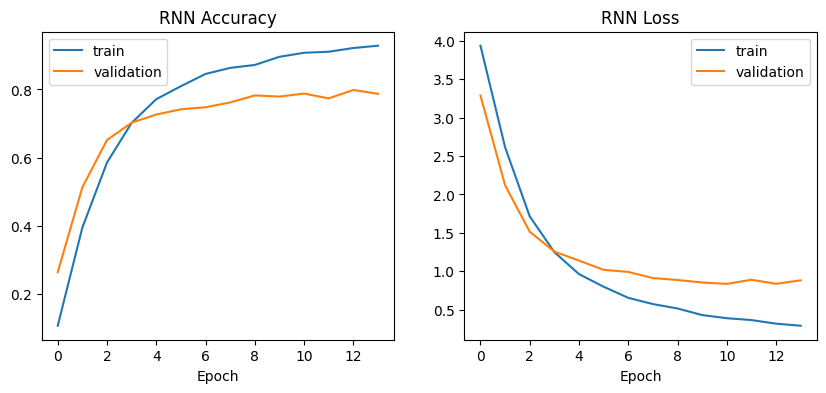

Validation loss: 0.8346
Validation accuracy: %78.79


In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)                                   # sol grafik: doğruluk
plt.plot(rnn_history.history["accuracy"], label="train")
plt.plot(rnn_history.history["val_accuracy"], label="validation")
plt.title("RNN Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)                                   # sağ grafik: hata
plt.plot(rnn_history.history["loss"], label="train")
plt.plot(rnn_history.history["val_loss"], label="validation")
plt.title("RNN Loss"); plt.xlabel("Epoch"); plt.legend()

plt.show()

val_loss, val_accuracy = rnn_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: %{val_accuracy * 100:.2f}")

**Save to trained model**

In [39]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)
rnn_model.save("models/rnn_model.keras")

print("RNN modeli kaydedildi.")

RNN modeli kaydedildi.


Preprocessing information saved

In [40]:
import json

preprocessing = {
    "vocabulary": vectorizer.get_vocabulary(),
    "categories": encoder.classes_.tolist(),
    "max_len": MAX_LEN,
    "max_tokens": MAX_WORDS,
    "standardize": "lower_and_strip_punctuation",
    "split": "whitespace"
}

with open("models/preprocessing.json", "w", encoding="utf-8") as file:
    json.dump(preprocessing, file, ensure_ascii=False, indent=4)

print("Ön işleme bilgileri kaydedildi.")

Ön işleme bilgileri kaydedildi.


**Build the LSTM Model**

In [41]:
tf.keras.utils.set_random_seed(42)   # her model aynı rastgelelikle başlasın (adil karşılaştırma)

lstm_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),                            # girdi: 30 sayılık mesaj
    layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),   # kelime → 128 sayılık vektör
    layers.LSTM(64),                                           # ← RNN'den tek fark burası
    layers.Dropout(0.3),                                       # ezberlemeyi azalt
    layers.Dense(NUM_CLASSES, activation="softmax")            # 77 kategori için olasılık
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 348,941 (1.33 MB)

 Trainable params: 348,941 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

**Train the LSTM**

In [16]:
early_stop = EarlyStopping(
    monitor="val_loss",          # deneme sınavındaki hatayı izle
    patience=3,                  # 3 epoch iyileşme olmazsa dur
    restore_best_weights=True    # en iyi epoch'a geri dön
)

start = time.time()              # kronometreyi başlat

lstm_history = lstm_model.fit(
    X_train, y_train,                    # çalışma verisi
    validation_data=(X_val, y_val),      # her epoch sonunda deneme sınavı
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

lstm_train_time = time.time() - start    # geçen süre
print(f"LSTM eğitim süresi: {lstm_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.1396 - loss: 3.7571 - val_accuracy: 0.3769 - val_loss: 2.7935
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.4898 - loss: 2.1415 - val_accuracy: 0.6484 - val_loss: 1.5514
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6943 - loss: 1.2670 - val_accuracy: 0.7472 - val_loss: 1.0665
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7967 - loss: 0.8579 - val_accuracy: 0.7832 - val_loss: 0.8692
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8531 - loss: 0.6344 - val_accuracy: 0.7972 - val_loss: 0.7569
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8871 - loss: 0.4946 - val_accuracy: 0.8125 - val_loss: 0.7071
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9085 - loss: 0.4028 - val_accuracy: 0.8139 - val_loss: 0.6818
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9266 - loss: 0.3255 - val_accuracy:

**LSTM Training Curves**

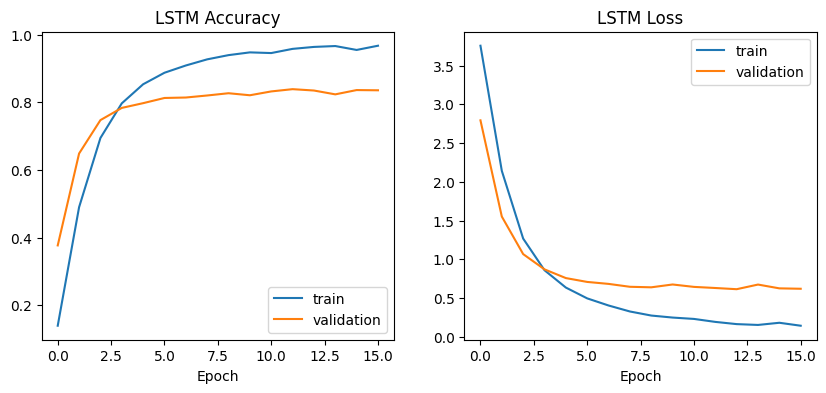

Validation loss: 0.6132
Validation accuracy: %83.46


In [17]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)                                          # sol: doğruluk
plt.plot(lstm_history.history["accuracy"], label="train")
plt.plot(lstm_history.history["val_accuracy"], label="validation")
plt.title("LSTM Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)                                          # sağ: hata
plt.plot(lstm_history.history["loss"], label="train")
plt.plot(lstm_history.history["val_loss"], label="validation")
plt.title("LSTM Loss"); plt.xlabel("Epoch"); plt.legend()

plt.show()

val_loss, val_accuracy = lstm_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: %{val_accuracy * 100:.2f}")

Save to trained model

In [18]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

lstm_model.save("models/lstm_model.keras")

print("LSTM modeli kaydedildi.")

LSTM modeli kaydedildi.


**Build the GRU model**

In [19]:
tf.keras.utils.set_random_seed(42)  # tekrarlanabilirlik için

gru_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,), dtype="int64"),
    layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
    layers.GRU(64),                         # GRU katmanı
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 336,781 (1.28 MB)

 Trainable params: 336,781 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

train the GRU

In [20]:
early_stop_gru = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

start = time.perf_counter()

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_gru],
    shuffle=True
)

gru_train_time = time.perf_counter() - start

print(f"GRU eğitim süresi: {gru_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.1230 - loss: 3.8085 - val_accuracy: 0.3336 - val_loss: 2.9315
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4455 - loss: 2.2173 - val_accuracy: 0.6024 - val_loss: 1.6673
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6630 - loss: 1.3442 - val_accuracy: 0.7058 - val_loss: 1.1598
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7772 - loss: 0.9218 - val_accuracy: 0.7732 - val_loss: 0.9236
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8349 - loss: 0.6755 - val_accuracy: 0.7932 - val_loss: 0.8049
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8805 - loss: 0.5246 - val_accuracy: 0.8139 - val_loss: 0.7462
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9010 - loss: 0.4281 - val_accuracy: 0.8172 - val_loss: 0.7022
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9209 - loss: 0.3478 - val_accuracy: 

GRU training Curves

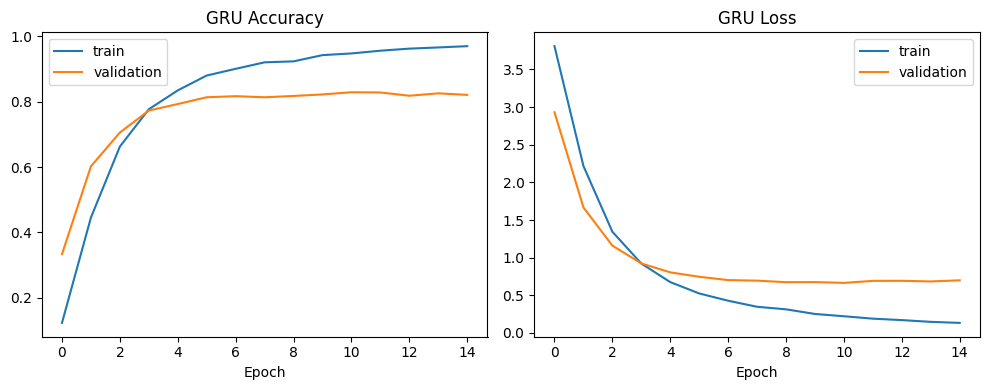

GRU validation loss: 0.6653
GRU validation accuracy: %82.92


In [21]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)  # sol: doğruluk
plt.plot(gru_history.history["accuracy"], label="train")
plt.plot(gru_history.history["val_accuracy"], label="validation")
plt.title("GRU Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)  # sağ: hata
plt.plot(gru_history.history["loss"], label="train")
plt.plot(gru_history.history["val_loss"], label="validation")
plt.title("GRU Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

gru_val_loss, gru_val_accuracy = gru_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"GRU validation loss: {gru_val_loss:.4f}")
print(f"GRU validation accuracy: %{gru_val_accuracy * 100:.2f}")

Save to trained model

In [22]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

gru_model.save("models/gru_model.keras")

print("GRU modeli kaydedildi.")

GRU modeli kaydedildi.


Build the 1D-CNN model

In [23]:
tf.keras.utils.set_random_seed(42)

cnn_model = models.Sequential([
    layers.Input(shape=(MAX_LEN,), dtype="int64"),
    layers.Embedding(VOCAB_SIZE, EMBED_DIM),
    layers.Conv1D(filters=64, kernel_size=3, activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 30, 128)        │       294,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 28, 64)         │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 77)             │         5,005 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 324,173 (1.24 MB)

 Trainable params: 324,173 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Train the 1D-CNN

In [24]:
early_stop_cnn = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

start = time.perf_counter()

cnn_history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop_cnn]
)

cnn_train_time = time.perf_counter() - start

print(f"1D-CNN eğitim süresi: {cnn_train_time:.1f} saniye")

Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.1551 - loss: 3.8289 - val_accuracy: 0.4623 - val_loss: 2.5820
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5475 - loss: 1.8586 - val_accuracy: 0.7258 - val_loss: 1.2042
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7078 - loss: 1.0898 - val_accuracy: 0.8025 - val_loss: 0.8412
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7965 - loss: 0.7733 - val_accuracy: 0.8232 - val_loss: 0.6842
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8383 - loss: 0.6054 - val_accuracy: 0.8379 - val_loss: 0.6077
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8699 - loss: 0.4827 - val_accuracy: 0.8559 - val_loss: 0.5652
Epoch 7/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8941 - loss: 0.4083 - val_accuracy: 0.8619 - val_loss: 0.5349
Epoch 8/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9043 - loss: 0.3502 - val_accuracy: 

GRU training Curves

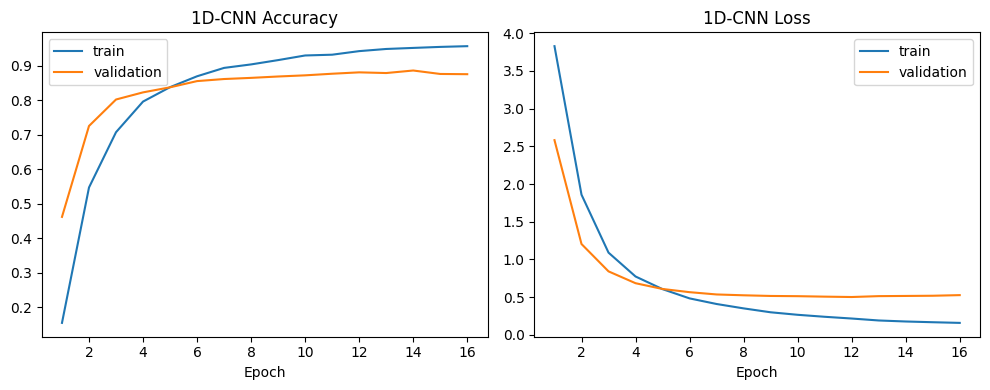

1D-CNN validation loss: 0.5010
1D-CNN validation accuracy: %88.13


In [25]:
import matplotlib.pyplot as plt

epoch_numbers = range(1, len(cnn_history.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, cnn_history.history["accuracy"], label="train")
plt.plot(epoch_numbers, cnn_history.history["val_accuracy"], label="validation")
plt.title("1D-CNN Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, cnn_history.history["loss"], label="train")
plt.plot(epoch_numbers, cnn_history.history["val_loss"], label="validation")
plt.title("1D-CNN Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

cnn_val_loss, cnn_val_accuracy = cnn_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print(f"1D-CNN validation loss: {cnn_val_loss:.4f}")
print(f"1D-CNN validation accuracy: %{cnn_val_accuracy * 100:.2f}")

Saved to trained Model

In [26]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

cnn_model.save("models/cnn_model.keras")

print("1D-CNN modeli kaydedildi.")

1D-CNN modeli kaydedildi.


**Model Builder Function**

In [ ]:
def build_model(model_type, units, dropout):
    tf.keras.utils.set_random_seed(42)
    model = models.Sequential()
    model.add(layers.Input(shape=(MAX_LEN,)))
    model.add(layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=(model_type != "cnn")))

    if model_type == "rnn":
        model.add(layers.SimpleRNN(units))
    elif model_type == "lstm":
        model.add(layers.LSTM(units))
    elif model_type == "gru":
        model.add(layers.GRU(units))
    elif model_type == "cnn":
        model.add(layers.Conv1D(units, 3, activation="relu"))
        model.add(layers.GlobalMaxPooling1D())

    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

**Training Function**

In [ ]:
def train_model(model):
    early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE,
                        callbacks=[early_stop], verbose=0)
    train_time = time.perf_counter() - start
    return history, train_time

**Hyperparameter Search on Validation Set**

In [ ]:
results = []
best_models = {}
best_histories = {}

for model_type in ["rnn", "lstm", "gru", "cnn"]:
    best_val = 0
    for units in [64, 128]:
        for dropout in [0.3, 0.5]:
            model = build_model(model_type, units, dropout)
            history, train_time = train_model(model)
            _, train_acc = model.evaluate(X_train, y_train, verbose=0)
            _, val_acc = model.evaluate(X_val, y_val, verbose=0)

            results.append({"model": model_type, "units": units, "dropout": dropout,
                            "epochs": len(history.history["loss"]),
                            "train_acc": round(train_acc, 3), "val_acc": round(val_acc, 3),
                            "gap": round(train_acc - val_acc, 3),
                            "train_time_s": round(train_time, 1)})
            print(f"{model_type:5} units={units:3} dropout={dropout} → val_acc={val_acc:.3f} ({train_time:.0f} sn)")

            if val_acc > best_val:
                best_val = val_acc
                best_models[model_type] = model
                best_histories[model_type] = history

results_df = pd.DataFrame(results)
results_df

**Save Best Model**

In [ ]:
for name, model in best_models.items():
    model.save(f"models/{name}_best.keras")
results_df.to_csv("models/validation_results.csv", index=False)
print("Kaydedildi:", list(best_models.keys()))